# `HaloGTF` `v1.0` demo

## Import

In [1]:
from pathlib import Path
import numpy as np
import halogtf as gtf
from halogtf.io.read import load_snapshot_bundle, extract_snapshot_indices


## Instantiate config object

In [2]:
config = gtf.Config()
config.scatter.model = "rutherford"  # You can choose "moller" (Møller scattering) too.
config.scatter.w = 30.0  # km/s; try 100.0 for weaker velocity dependence, or float("inf") for hard spheres.
config.io.base_dir = str(Path.cwd() / "demo_outputs")


This holds all of the parameters that are used to instantiate a State object. These can be modified before instantiating the State. Once the State object exists, the config object becomes an attribute of the state.

The current parameter groups are `init`, `grid`, `scatter`, `num`, `stop`, `io`, and `cosmo`. Scattering parameters live in `config.scatter`, numerical tolerances in `config.num`, and stopping limits in `config.stop`. The default `scatter.smfp_order=2`, `scatter.alph=0.57`, and `scatter.c=0.86` select the adopted Rutherford second-order calibration; choosing Møller does not automatically choose a separately calibrated parameter pair.


In [3]:
config

Config(
  io=IOParams(model_no='<not evaluated>', model_dir='<not evaluated>', base_dir='/Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/demo_outputs', nlog=100000, nupdate=1000, t_evol=True, profiles=True, drho_prof=0.1, drho_tevol=0.01, overwrite=True, chatter=True),
  grid=GridParams(drfrac_init=0.05, drfrac_max=0.1, drfrac_min=0.01, grid_splitting=True, rmax=200.0, rmin=0.01),
  init=NFWParams(Mvir=3000000000.0, cvir=20.0),
  scatter=ScatterParams(a=2.256758, alph=0.57, b=1.3847, c=0.86, model='rutherford', model_id=0, sigma_m_0=10.0, smfp_order=2, w=30.0),
  num=NumericalParams(du_boost=100.0, eps_dr=1e-12, eps_du=0.0001, epsabs=1e-06, epsrel=1e-06, kn_threshold=0.01, kn_width=1.0, max_iter_dr=100, max_iter_du=10),
  stop=StopParams(rho0_halt=100000.0, t_halt=1000.0)
  cosmo=CosmoParams(xhubble=0.7, Omega_m=0.3, Delta_vir=200.0, z=0.0)
)

Change to a truncated NFW profile, optionally modify parameters.

Numerical tolerances can affect convergence depending on the initial profile. The energy-change tolerance is `config.num.eps_du` (default `1e-4`).

Truncated-NFW initialization that can a couple of minute. Below we load a precomputed initial condition file instead.


In [4]:
config.init = ("truncated_nfw", {
    "Mvir": 3.0e9,  # Msun/h
    "cvir": 20.0,
    "Zt": 0.05938,
    "deltaP": 1.0e-5,
})

config


Config(
  io=IOParams(model_no='<not evaluated>', model_dir='<not evaluated>', base_dir='/Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/demo_outputs', nlog=100000, nupdate=1000, t_evol=True, profiles=True, drho_prof=0.1, drho_tevol=0.01, overwrite=True, chatter=True),
  grid=GridParams(drfrac_init=0.05, drfrac_max=0.1, drfrac_min=0.01, grid_splitting=True, rmax=200.0, rmin=0.01),
  init=TruncatedNFWParams(Mvir=3000000000.0, cvir=20.0, Zt=0.05938, deltaP=1e-05),
  scatter=ScatterParams(a=2.256758, alph=0.57, b=1.3847, c=0.86, model='rutherford', model_id=0, sigma_m_0=10.0, smfp_order=2, w=30.0),
  num=NumericalParams(du_boost=100.0, eps_dr=1e-12, eps_du=0.0001, epsabs=1e-06, epsrel=1e-06, kn_threshold=0.01, kn_width=1.0, max_iter_dr=100, max_iter_du=10),
  stop=StopParams(rho0_halt=100000.0, t_halt=1000.0)
  cosmo=CosmoParams(xhubble=0.7, Omega_m=0.3, Delta_vir=200.0, z=0.0)
)

The model number is automatically chosen as the first unused number in `config.io.base_dir` when first accessed. This can be overridden by specifying `model_no`. The examples below explicitly use Model00000, Model00001, and Model00002 under `demo_outputs`; with the default `config.io.overwrite=True`, rerunning initialization can overwrite their existing outputs. Set `overwrite=False` to reject existing model directories.


In [5]:
config.io.model_no = 0

# Instantiate the state

Construct the state from the config object, optionally loading an initial profile with `ic_filepath`. If an IC file is specified that does not exist yet, it gets automatically created.  Loading it starts a new simulation and still performs hydrostatic relaxation. `State.from_dir()` is not implemented; reading existing output files is demonstrated below instead.


In [6]:
ic_filepath = Path.cwd() / "ics" / "truncated_nfw_M3e9_c20_Zt005938.dat"
state = gtf.State.from_config(config, ic_filepath=str(ic_filepath))
model_dir = Path(config.io.base_dir) / config.io.model_dir


Computing characteristic parameters for simulation...
Setting up radial grid...
	Radial grid set up with 200 cells and uniform dr/r = 4.9771e-02 outside the innermost bin.
IC file /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/ics/truncated_nfw_M3e9_c20_Zt005938.dat not found. Creating IC file at that location...
Computing characteristic parameters for simulation...
Generating lookup for rho(phi)...
Computing potential profile for truncated NFW halo...
Integrating Poisson equation outward: r = 0.005000, phi = 0.938128

/Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/halogtf/profiles/truncated_nfw.py:64: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  result, _ = quad(integrand_for_rho, 0.0, float(phi),


Integrating Poisson equation outward: r = 116.793421, phi = -0.000002
Setting up radial grid...
	Radial grid set up with 189 cells and uniform dr/r = 4.9769e-02 outside the innermost bin.
Initializing profiles...
Computing Menc: r = 115.625, m = 2.658
Generating lookup for v2 integrand...
Computing v2: r = 112.819, v2 = 0.000
Initial condition file written to /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/ics/truncated_nfw_M3e9_c20_Zt005938.dat.
Loading initial conditions from /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/ics/truncated_nfw_M3e9_c20_Zt005938.dat ...


/Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/halogtf/state.py:340: RuntimeWarning: Radial grid in IC file does not match the grid defined by the current configuration.  Using IC file grid.
  warnings.warn("Radial grid in IC file does not match the grid defined by the current configuration.  Using IC file grid.", RuntimeWarning)


Ensuring initial hydrostatic equilibrium...
	Initial pressure correction applied. HE residual improved 1.380e+00 -> 1.621e-14.
Hydrostatic equilibrium achieved in 7 iterations. Max |dr/r| = 2.69e-16.  HE res 1.0322285724502194.
State initialized.
Created directory: /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/demo_outputs/Model00000
Characteristic parameters written to char_params.txt
Model information written to model_metadata.txt
Initial profiles written to disk.


At this point, a `model_metadata.txt` file has been written to the disk, as well as initial profiles.

Plot the current state (initial state):

(<Figure size 600x500 with 1 Axes>,
 <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='rho'>)

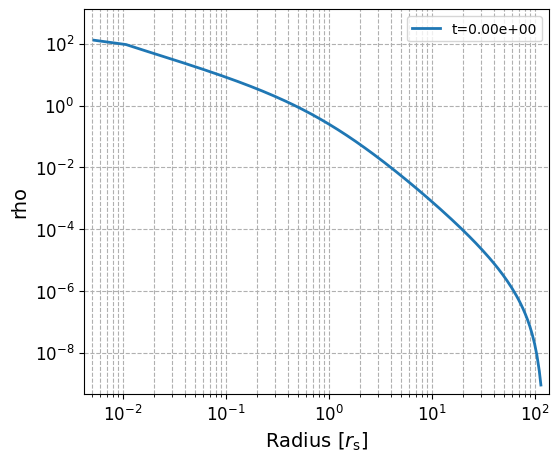

In [7]:
gtf.plot_snapshots(state, grid=True)

These, as well as all other plots, can be optionally saved to disk using the `filepath` keyword.

`show=True` prints the plot to stdout even when saving to a file.

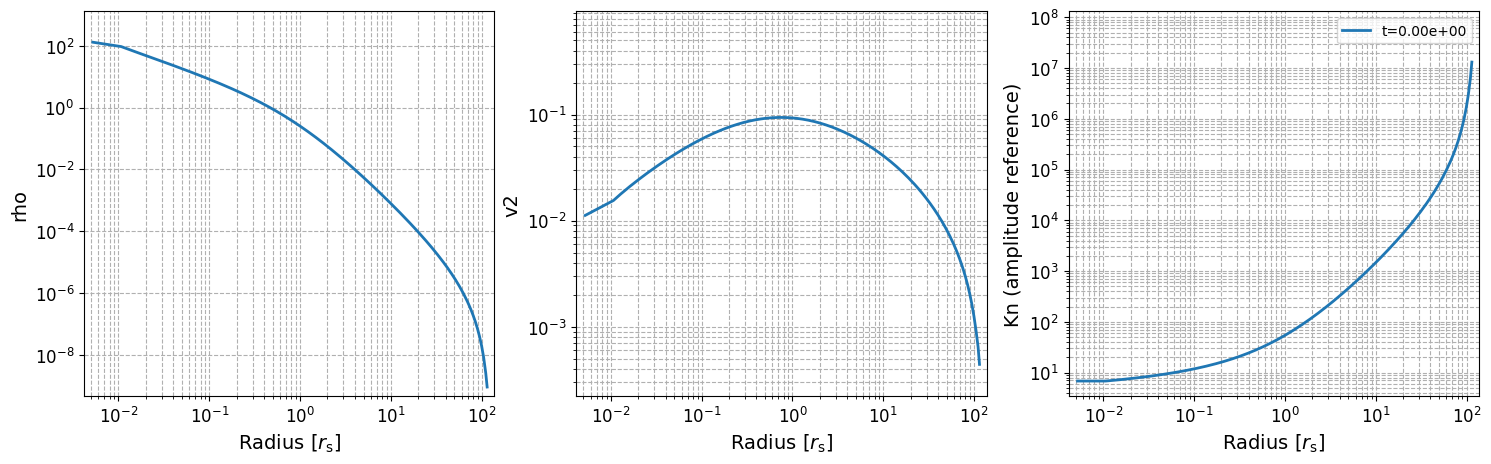

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='rho'>,
        <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='v2'>,
        <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='Kn (amplitude reference)'>],
       dtype=object))

In [8]:
gtf.plot_snapshots(state, grid=True, profiles=['rho', 'v2', 'kn'],
                   filepath=str(model_dir / 'initial.png'), show=True)


# Run simulation

In each integration step:
- `dt` is determined based on the current state and tolerance parameters set in `config`.
- "Conduction step": the internal energy is updated based on the luminosity at the bin edges.  This is done to linear order (heat is only conducted in adjacent bins).  This updates `u`, and in turn, `p` (asserting $p_i = (2/3) u_i * \rho_i$)
- "Revirialization step": Now that `p` has been updated with $\rho$ unchanged, hydrostatic equilibrium must be reestablished by adjusting the edges of the radial bin, keeping `M` invariant (Lagrangian framework), but updating `rho` and `p`.
- `v2`, `u` and other derived quantities are updated based on the results of the revirialization step.


By default, the system evolves until one of three stop conditions occur:
- innermost-cell density exceeds `config.stop.rho0_halt` (default `1e5` in `rho_s` units), checked only after `state.t > 50`
- time reaches `config.stop.t_halt` (default `1000` in `t_s` units)
- central density becomes a nan

Additional conditions can be added with keyword arguments into `run()`: `steps`, `stoptime`, `rho0`

`run(stoptime=...)` requests an additional duration in `t_s` units, while `run(rho0=...)` checks the innermost-cell density immediately after each step. Saved `rho_c` is instead the mean density inside the half-central-density radius. Time uses the current reference-moment scale `t_s`, based on a common dispersion `0.33*v_s`; use the `time_Gyr` output column for physical-time comparisons. The `run()` call below retains the full-run example; you can pass `steps=100` for a short check.


In [9]:
state.run()

Initial profiles written to disk.
Time evolution file initialized.
Log file initialized:
      step           time           <dt>       n           rho0          v_max           kn_c      kn_cond_c     eps_du_eff       <du lim>       <dr lim>   <n_retry_du>    <n_iter_dr>   n_split   n_merge
         0   0.000000e+00            N/A     189   1.300763e+02   3.063431e-01   6.934146e+00   1.585976e+01   4.876301e-04            N/A            N/A            N/A            N/A         0         0
Simulation halted: central density exceeds halting value
Time evolution file finalized.
     30314   3.016299e+02   9.950185e-03     216   1.000603e+05   4.935122e-01   6.346998e-02   2.446094e+00   9.321536e-04   9.881219e-01   3.824273e-04   2.738009e-03   2.000891e+00        27         0
Total time for run(): 10.40s


If a simulation has already been fully or partially completed, we can also read a snapshot from its directory of output files:

Use the optional `snapshot` keyword to select a saved index other than the latest one. This returns a dictionary of saved data, not a restartable State; the live `state` above is retained for the plotting examples.


In [10]:
snapshot = load_snapshot_bundle(str(model_dir))  # Latest saved snapshot
initial_snapshot = load_snapshot_bundle(str(model_dir), snapshot=0)


# Inspect/present results

(<Figure size 700x500 with 1 Axes>,
 <Axes: xlabel='Time [$t_\\mathrm{s}$]', ylabel='Core conductivity-effective Kn'>)

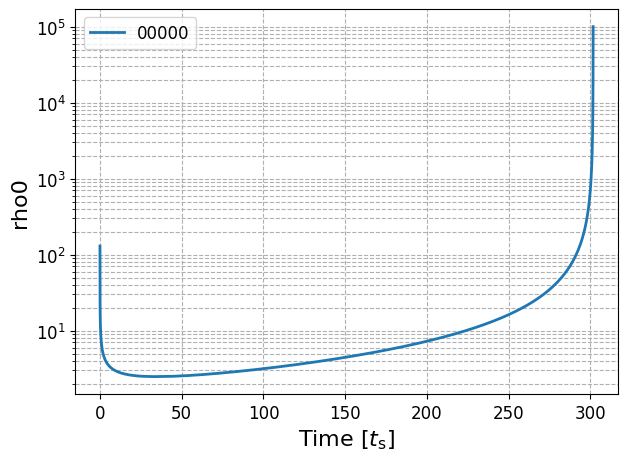

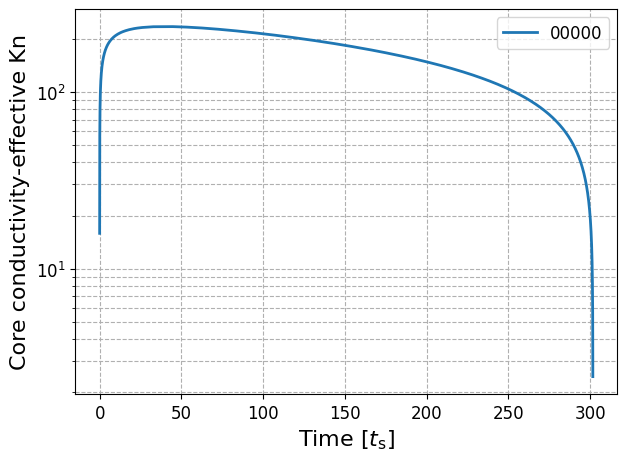

In [11]:
state.plot_time_evolution(grid=True)  # Default: rho0, the innermost-cell density
state.plot_time_evolution(grid=True, quantity='kn_cond_c')


`plot_time_evolution` also exists as a standalone function and can be used to compare multiple simulations in the same directory:

Here, Model00000 is the truncated NFW profile evolved above, Model00001 is an alpha-beta-gamma profile, and Model00002 is an NFW profile. The next cell creates and evolves the latter two before plotting, so it does not depend on the repository's legacy example outputs.

The examples use `w=30`, `100`, and `inf` km/s respectively to illustrate stronger velocity dependence, weaker velocity dependence, and the hard-sphere limit for these halo scales; these are illustrative choices, not three separately fitted calibrations. Because both the initial profiles and scattering laws differ, this is not a controlled comparison of `w` alone. The horizontal axis is each model's own `t_s` unit, and `quantity='rho_c'` plots mean core density rather than central density.


Computing characteristic parameters for simulation...
Setting up radial grid...
	Radial grid set up with 200 cells and uniform dr/r = 4.9771e-02 outside the innermost bin.
Initializing profiles...
Ensuring initial hydrostatic equilibrium...
	Initial pressure correction applied. HE residual improved 1.454e+02 -> 4.006e-12.
Hydrostatic equilibrium achieved in 4 iterations. Max |dr/r| = 2.90e-16.  HE res 1.001384160357431.
State initialized.
Created directory: /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/demo_outputs/Model00001
Characteristic parameters written to char_params.txt
Model information written to model_metadata.txt
Initial profiles written to disk.
Initial profiles written to disk.
Time evolution file initialized.
Log file initialized:
      step           time           <dt>       n           rho0          v_max           kn_c      kn_cond_c     eps_du_eff       <du lim>       <dr lim>   <n_retry_du>    <n_iter_dr>   n_split   n_merge
         0   0.000000e+

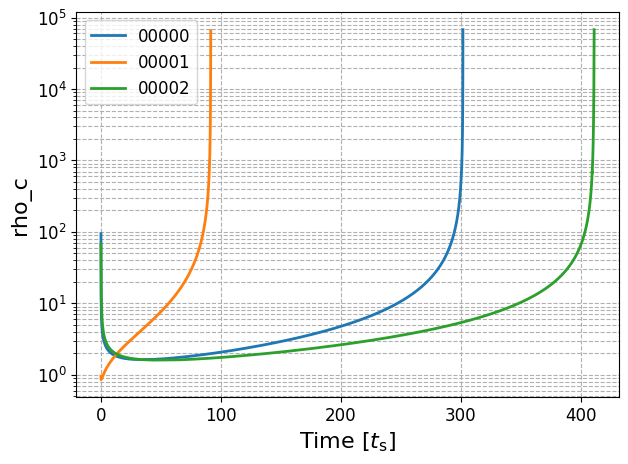

(<Figure size 700x500 with 1 Axes>,
 <Axes: xlabel='Time [$t_\\mathrm{s}$]', ylabel='rho_c'>)

In [12]:
# Additional initial profiles from the original comparison example.
config_abg = gtf.Config(
    init="abg",
    scatter={"model": "rutherford", "w": 100.0},  # "moller" is also supported.
    io={"base_dir": config.io.base_dir, "model_no": 1},
)
state_abg = gtf.State.from_config(config_abg)
state_abg.run()

config_nfw = gtf.Config(
    init="nfw",
    scatter={"model": "rutherford", "w": float("inf")},  # Hard-sphere limit; identical for "moller".
    io={"base_dir": config.io.base_dir, "model_no": 2},
)
state_nfw = gtf.State.from_config(config_nfw)
state_nfw.run()

gtf.plot_time_evolution(
    models=[0,1,2],
    quantity='rho_c',
    grid=True,
    base_dir=config.io.base_dir,
    filepath=str(Path(config.io.base_dir) / 'compare.png'),
    show=True
    )


When plotting snapshots, the index `-1` corresponds to the last snapshot. For the multiple-snapshot example, select indices from `snapshot_conversion.txt` so that every requested snapshot exists even if the run is short.


(<Figure size 600x500 with 1 Axes>,
 <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='rho'>)

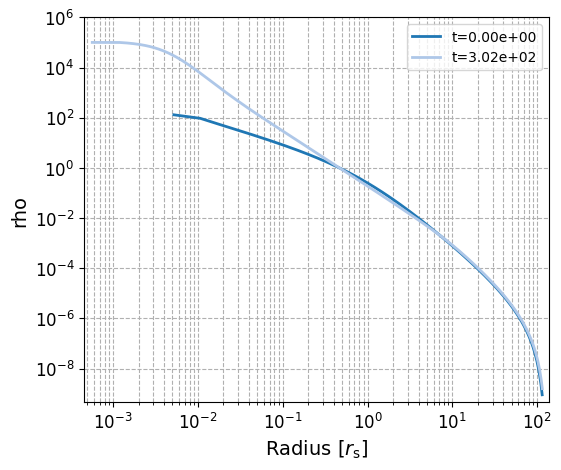

In [13]:
state.plot_snapshots(grid=True, snapshots=[0,-1])

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='rho'>,
        <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='v2'>,
        <Axes: xlabel='Radius [$r_\\mathrm{s}$]', ylabel='Kn (amplitude reference)'>],
       dtype=object))

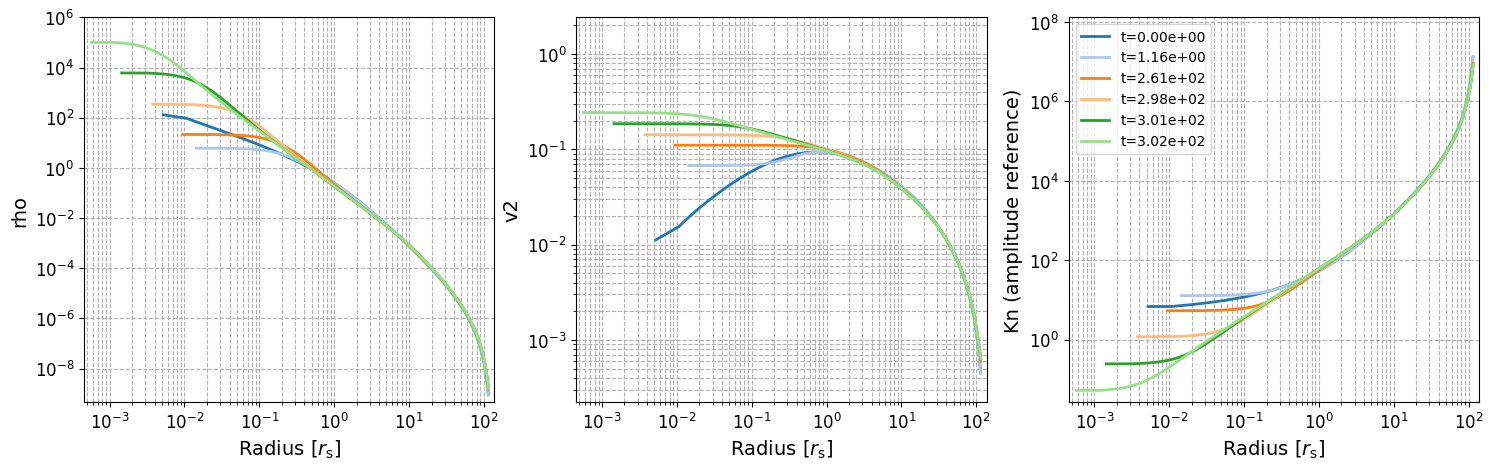

In [14]:
available = extract_snapshot_indices(str(model_dir))['index']
selection = np.linspace(0, len(available) - 1, min(6, len(available)), dtype=int)
snapshots = [int(available[i]) for i in selection]

state.plot_snapshots(grid=True, snapshots=snapshots, profiles=['rho', 'v2', 'kn'])


# Animate the evolution

This example requires `ffmpeg` to be installed and available on your PATH. Add `parallel=False` to render frames serially if needed in your notebook environment.


In [15]:
state.make_movie(grid=True, profiles=['rho', 'v2', 'kn'])

Getting time evolution data...
Getting axis limits...
Generating 149 frames using 7 parallel processes...


Frames: 100%|██████████| 149/149 [00:13<00:00, 10.70frame/s]


Compiling into a movie using ffmpeg...
Deleting frames...
Movie saved to /Users/yaronetokayer/YaleDrive/Research/Codes/halogtf/examples/demo_outputs/Model00000/movie_deluxe.mp4


`make_movie()` and `plot_snapshots()` also exist as standalone functions and not only as State methods.  See, e.g., `help(gtf.make_movie)` for usage.

In [16]:
help(gtf.make_movie), help(gtf.plot_snapshots)

Help on function make_movie in module halogtf.plot.snapshot:

make_movie(model, parallel=True, **kwargs)
    Animate profiles using the deluxe renderer with fixed axis limits.

    parallel=True uses separate rendering processes; False renders serially.
    profiles defaults to ['rho', 'v2']. insets=None adds rho0 to the first
    panel; insets=False disables all insets. A per-panel list of column names
    and None entries is also accepted. time_evolution.txt is required only
    for insets or marked radii.

    Other options: xaxis, add_radii, filepath, base_dir, grid, and fps.
    The parallel renderer additionally accepts vertical.
    Requires ffmpeg. See make_movie_deluxe_serial/parallel for details.

Help on function plot_snapshots in module halogtf.plot.snapshot:

plot_snapshots(model, snapshots=None, profiles='rho', xaxis=None, base_dir=None, filepath=None, show=False, grid=False, for_movie=False)
    Plot up to three profiles at specified points in time for one simulation

  

(None, None)